Loaded: (367, 367, 3) (373, 373, 3)


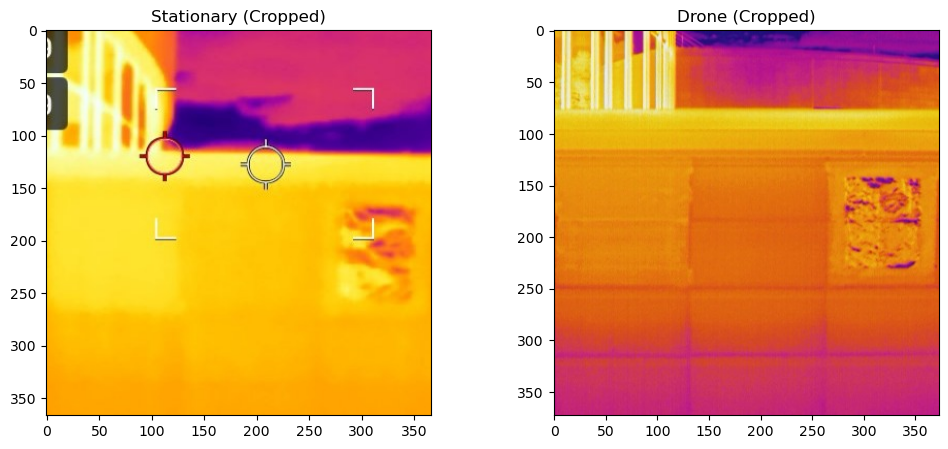

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import seaborn as sns

# ----------------------------
# UPDATE THESE PATHS
# ----------------------------
stat_path = r"C:\Users\murat\Downloads\STAT CROPPED NOV 17.JPG"
drone_path = r"C:\Users\murat\Downloads\DRONE CROPPED NOV 17.JPG"

# Load images (RGB for plotting, grayscale for pixel math)
stat_rgb = cv2.cvtColor(cv2.imread(stat_path), cv2.COLOR_BGR2RGB)
drone_rgb = cv2.cvtColor(cv2.imread(drone_path), cv2.COLOR_BGR2RGB)

stat_gray = cv2.cvtColor(stat_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
drone_gray = cv2.cvtColor(drone_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)

print("Loaded:", stat_rgb.shape, drone_rgb.shape)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(stat_rgb); plt.title("Stationary (Cropped)")
plt.subplot(1,2,2); plt.imshow(drone_rgb); plt.title("Drone (Cropped)")
plt.show()


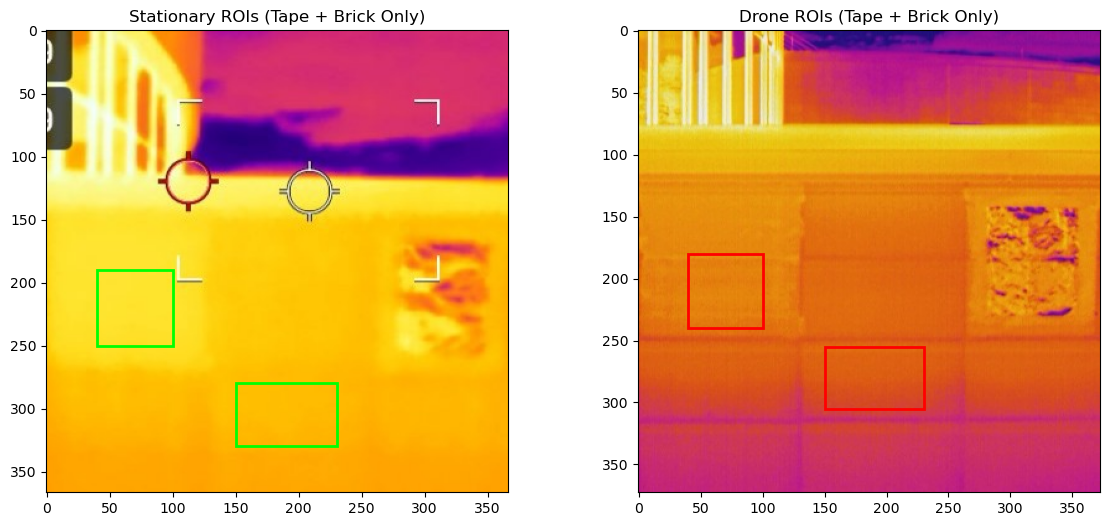

In [2]:
# =============================================
# UPDATED ROIs - ONLY TAPE AND BRICK (NO FOIL)
# =============================================
ROI_STAT = [
    (40, 190, 100, 250),    # Black tape
    (150, 280, 230, 330)    # Background brick/wall
]
ROI_DRONE = [
    (40, 180, 100, 240),    # Black tape (match)
    (150, 255, 230, 305)    # Background brick/wall (match)
]

# Visualize the updated ROIs
fig, ax = plt.subplots(1,2, figsize=(14,6))
ax[0].imshow(stat_rgb); ax[0].set_title("Stationary ROIs (Tape + Brick Only)")
for (x1,y1,x2,y2) in ROI_STAT:
    ax[0].add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1,
                                   edgecolor='lime', linewidth=2, fill=False))
ax[1].imshow(drone_rgb); ax[1].set_title("Drone ROIs (Tape + Brick Only)")
for (x1,y1,x2,y2) in ROI_DRONE:
    ax[1].add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1,
                                   edgecolor='red', linewidth=2, fill=False))
plt.show()

In [3]:
# =============================================
# SIMPLE DENSE SAMPLING - All pixels within 1.5 std
# =============================================
stat_samples = []
drone_samples = []

for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_region = stat_gray[y1_s:y2_s, x1_s:x2_s].flatten()
    drone_region = drone_gray[y1_d:y2_d, x1_d:x2_d].flatten()
    
    # Filter to keep only stable pixels (within 1.5 std)
    stat_mean, stat_std = np.mean(stat_region), np.std(stat_region)
    drone_mean, drone_std = np.mean(drone_region), np.std(drone_region)
    
    stat_mask = np.abs(stat_region - stat_mean) <= 1.5 * stat_std
    drone_mask = np.abs(drone_region - drone_mean) <= 1.5 * drone_std
    valid_mask = stat_mask & drone_mask
    
    stat_filtered = stat_region[valid_mask]
    drone_filtered = drone_region[valid_mask]
    
    # Subsample to 300 points per ROI max
    if len(stat_filtered) > 300:
        indices = np.random.choice(len(stat_filtered), 300, replace=False)
        stat_filtered = stat_filtered[indices]
        drone_filtered = drone_filtered[indices]
    
    stat_samples.extend(stat_filtered)
    drone_samples.extend(drone_filtered)
    
    print(f"ROI {i+1}: {len(stat_filtered)} samples | "
          f"Stat: {stat_mean:.1f}±{stat_std:.1f} | "
          f"Drone: {drone_mean:.1f}±{drone_std:.1f}")

stat_samples = np.array(stat_samples)
drone_samples = np.array(drone_samples)

print(f"\n✓ Total calibration points: {len(stat_samples)}")

ROI 1: 300 samples | Stat: 214.4±1.4 | Drone: 145.4±4.0
ROI 2: 300 samples | Stat: 185.5±2.2 | Drone: 120.5±6.8

✓ Total calibration points: 600


In [4]:
# =============================================
# SIMPLE LINEAR REGRESSION ONLY
# =============================================
X_train = drone_samples.reshape(-1, 1)
y_train = stat_samples

# Fit linear model
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_train)

# Calculate statistics
r2 = r2_score(y_train, y_pred)
slope = model.coef_[0]
intercept = model.intercept_
rmse = np.sqrt(np.mean((y_train - y_pred)**2))

from scipy import stats
pearson_r, pearson_p = stats.pearsonr(X_train.flatten(), y_train)

print("="*60)
print("CALIBRATION MODEL")
print("="*60)
print(f"Equation: Stationary = {slope:.4f} × Drone + {intercept:.4f}")
print(f"R² = {r2:.4f}")
print(f"RMSE = {rmse:.2f} pixel values")
print(f"Pearson r = {pearson_r:.4f}")
print("="*60)

CALIBRATION MODEL
Equation: Stationary = 1.0945 × Drone + 53.7851
R² = 0.9220
RMSE = 4.01 pixel values
Pearson r = 0.9602


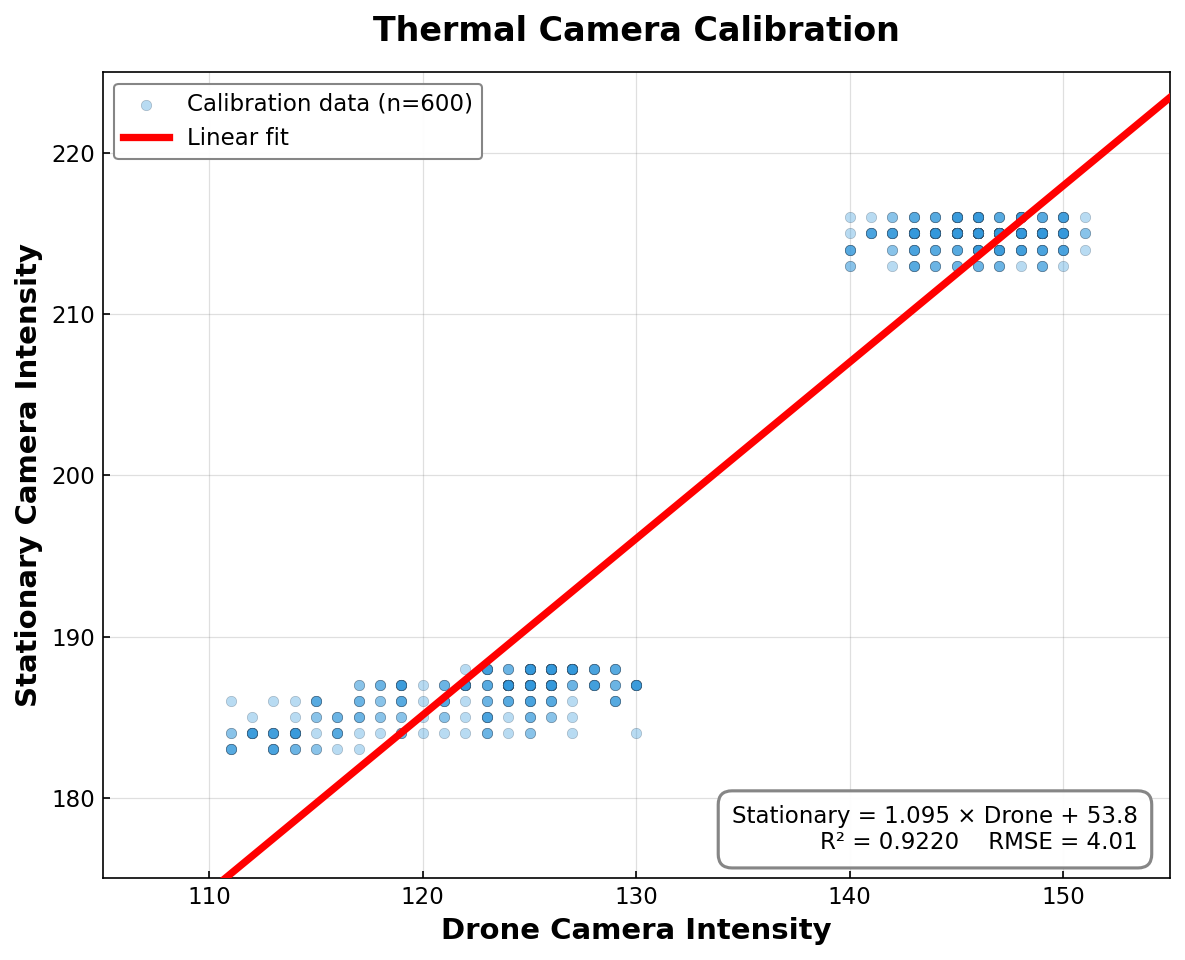

In [9]:
# =============================================
# SIMPLEST & CLEANEST (My recommendation)
# =============================================
fig, ax = plt.subplots(figsize=(8, 6.5), dpi=150)

# Single color, clean scatter
ax.scatter(drone_samples, stat_samples, alpha=0.35, s=25,
           color='#3498db', edgecolors='#2c3e50', linewidth=0.3,
           label=f'Calibration data (n={len(drone_samples)})')

# Calibration line - thicker and prominent
x_range = np.linspace(105, 155, 100)
y_fit = slope * x_range + intercept
ax.plot(x_range, y_fit, 'r-', linewidth=3.5, 
        label=f'Linear fit', zorder=10)

# Equation in cleaner format
equation_text = (f'Stationary = {slope:.3f} × Drone + {intercept:.1f}\n'
                f'R² = {r2:.4f}    RMSE = {rmse:.2f}')
ax.text(0.97, 0.03, equation_text, transform=ax.transAxes,
        fontsize=11, ha='right', va='bottom', family='sans-serif',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white', 
                  edgecolor='gray', linewidth=1.5, alpha=0.95))

# Clean labels
ax.set_xlabel('Drone Camera Intensity', fontsize=14, fontweight='600')
ax.set_ylabel('Stationary Camera Intensity', fontsize=14, fontweight='600')
ax.set_title('Thermal Camera Calibration', fontsize=16, fontweight='bold', pad=15)

# Professional grid
ax.grid(True, alpha=0.25, linestyle='-', linewidth=0.6, color='gray')
ax.set_axisbelow(True)

# Legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.95, edgecolor='gray')

# Limits
ax.set_xlim(105, 155)
ax.set_ylim(175, 225)

# Ticks
ax.tick_params(labelsize=11, direction='in', which='both')

plt.tight_layout()
plt.show()

In [10]:
# =============================================
# SEPARATE CALIBRATIONS FOR EACH ROI
# =============================================
from scipy import stats

# Prepare data for each ROI separately
roi_data = []

for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_region = stat_gray[y1_s:y2_s, x1_s:x2_s].flatten()
    drone_region = drone_gray[y1_d:y2_d, x1_d:x2_d].flatten()
    
    # Filter to stable pixels
    stat_mean, stat_std = np.mean(stat_region), np.std(stat_region)
    drone_mean, drone_std = np.mean(drone_region), np.std(drone_region)
    
    stat_mask = np.abs(stat_region - stat_mean) <= 1.5 * stat_std
    drone_mask = np.abs(drone_region - drone_mean) <= 1.5 * drone_std
    valid_mask = stat_mask & drone_mask
    
    stat_filtered = stat_region[valid_mask]
    drone_filtered = drone_region[valid_mask]
    
    # Subsample if needed
    if len(stat_filtered) > 300:
        indices = np.random.choice(len(stat_filtered), 300, replace=False)
        stat_filtered = stat_filtered[indices]
        drone_filtered = drone_filtered[indices]
    
    # Fit individual model
    X_roi = drone_filtered.reshape(-1, 1)
    y_roi = stat_filtered
    
    model_roi = LinearRegression()
    model_roi.fit(X_roi, y_roi)
    y_pred_roi = model_roi.predict(X_roi)
    
    r2_roi = r2_score(y_roi, y_pred_roi)
    rmse_roi = np.sqrt(np.mean((y_roi - y_pred_roi)**2))
    slope_roi = model_roi.coef_[0]
    intercept_roi = model_roi.intercept_
    
    roi_data.append({
        'name': ['Black Tape', 'Brick Wall'][i],
        'drone': drone_filtered,
        'stat': stat_filtered,
        'model': model_roi,
        'slope': slope_roi,
        'intercept': intercept_roi,
        'r2': r2_roi,
        'rmse': rmse_roi,
        'n': len(drone_filtered)
    })
    
    print(f"{roi_data[i]['name']}:")
    print(f"  y = {slope_roi:.3f}x + {intercept_roi:.1f}")
    print(f"  R² = {r2_roi:.4f}, RMSE = {rmse_roi:.2f}, n = {len(drone_filtered)}")
    print()

Black Tape:
  y = 0.039x + 209.2
  R² = 0.0149, RMSE = 0.78, n = 300

Brick Wall:
  y = 0.220x + 159.1
  R² = 0.5152, RMSE = 1.08, n = 300



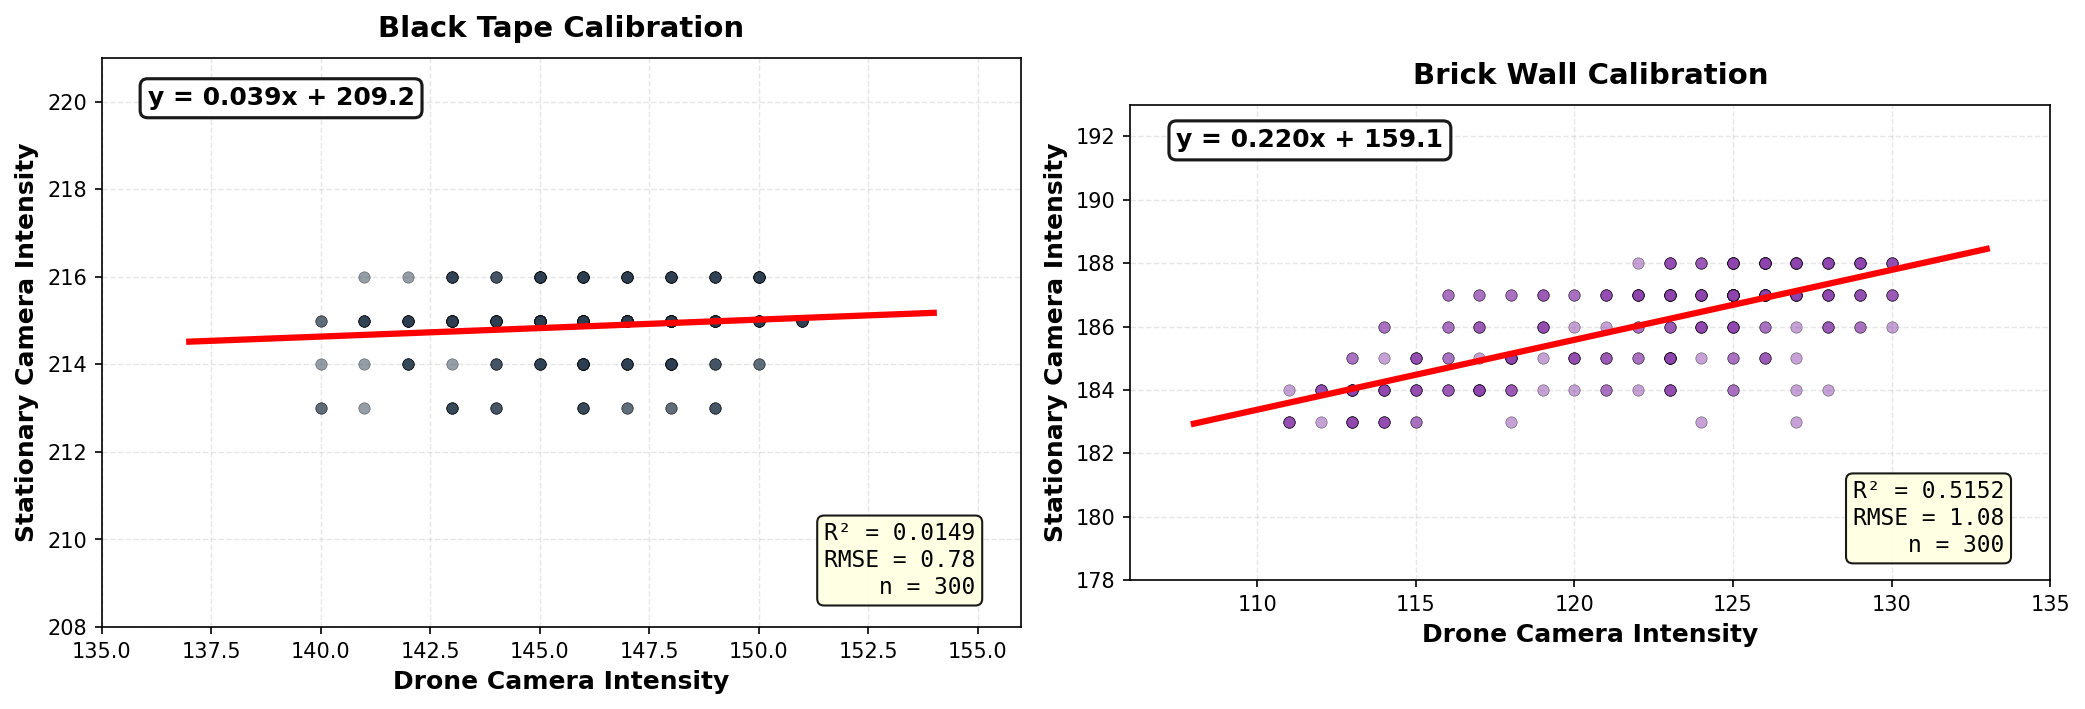

In [11]:
# =============================================
# SIDE-BY-SIDE PLOTS (Publication Style)
# =============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

colors = ['#2c3e50', '#8e44ad']  # Dark blue-gray for tape, purple for brick

for idx, (ax, data) in enumerate(zip(axes, roi_data)):
    # Scatter plot
    ax.scatter(data['drone'], data['stat'], 
               alpha=0.5, s=30, color=colors[idx], 
               edgecolors='black', linewidth=0.3)
    
    # Fit line
    x_range = np.linspace(data['drone'].min()-3, data['drone'].max()+3, 100)
    y_fit = data['slope'] * x_range + data['intercept']
    ax.plot(x_range, y_fit, 'r-', linewidth=3, label='Linear fit')
    
    # Equation and stats
    equation_text = f"y = {data['slope']:.3f}x + {data['intercept']:.1f}"
    ax.text(0.05, 0.95, equation_text, transform=ax.transAxes,
            fontsize=12, verticalalignment='top', fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, 
                      edgecolor='black', linewidth=1.5))
    
    stats_text = f"R² = {data['r2']:.4f}\nRMSE = {data['rmse']:.2f}\nn = {data['n']}"
    ax.text(0.95, 0.05, stats_text, transform=ax.transAxes,
            fontsize=11, ha='right', va='bottom', family='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))
    
    # Labels and title
    ax.set_xlabel('Drone Camera Intensity', fontsize=12, fontweight='bold')
    ax.set_ylabel('Stationary Camera Intensity', fontsize=12, fontweight='bold')
    ax.set_title(f'{data["name"]} Calibration', fontsize=14, fontweight='bold', pad=10)
    
    # Grid
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    
    # Equal aspect for visual consistency
    ax.set_aspect('equal', adjustable='box')
    
    # Set limits with margin
    margin = 5
    ax.set_xlim(data['drone'].min()-margin, data['drone'].max()+margin)
    ax.set_ylim(data['stat'].min()-margin, data['stat'].max()+margin)

plt.tight_layout()
plt.show()

In [6]:
# =============================================
# APPLY CALIBRATION
# =============================================
drone_calibrated = slope * drone_gray + intercept
drone_calibrated = np.clip(drone_calibrated, 0, 255).astype(np.uint8)

print("Calibrated Image Stats:")
print(f"  Min: {drone_calibrated.min()}, Max: {drone_calibrated.max()}")
print(f"  Mean: {drone_calibrated.mean():.1f} ± {drone_calibrated.std():.1f}")

Calibrated Image Stats:
  Min: 84, Max: 255
  Mean: 195.0 ± 34.5


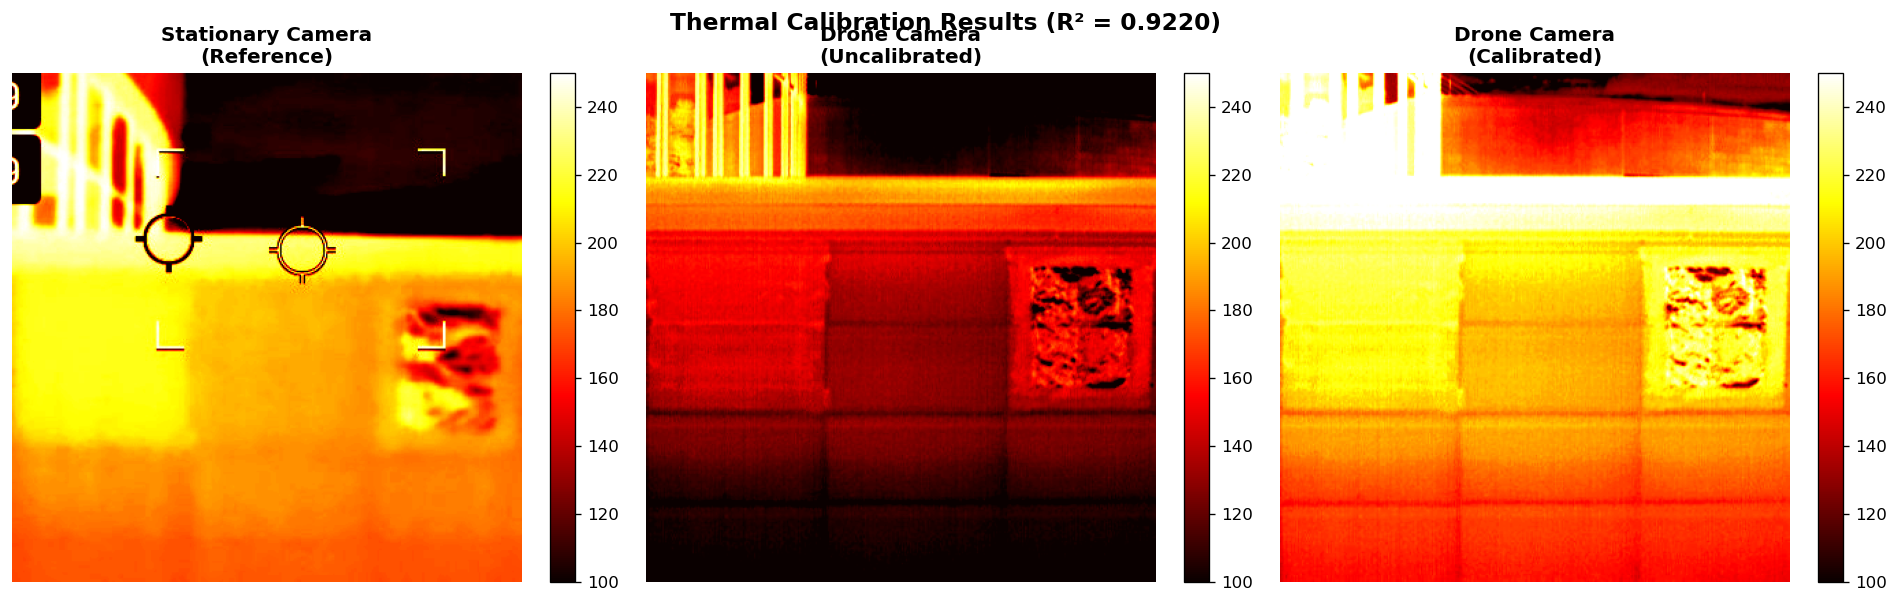

In [7]:
# =============================================
# SIMPLE BEFORE/AFTER COMPARISON
# =============================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=120)

# Use same color scale for comparison
vmin, vmax = 100, 250

im0 = axes[0].imshow(stat_gray, cmap='hot', vmin=vmin, vmax=vmax)
axes[0].set_title('Stationary Camera\n(Reference)', fontsize=12, fontweight='bold')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(drone_gray, cmap='hot', vmin=vmin, vmax=vmax)
axes[1].set_title('Drone Camera\n(Uncalibrated)', fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(drone_calibrated, cmap='hot', vmin=vmin, vmax=vmax)
axes[2].set_title('Drone Camera\n(Calibrated)', fontsize=12, fontweight='bold')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.suptitle(f'Thermal Calibration Results (R² = {r2:.4f})', 
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [8]:
# =============================================
# VALIDATION: Compare ROI means before/after
# =============================================
print("\n" + "="*70)
print("ROI VALIDATION")
print("="*70)

for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_mean = np.mean(stat_gray[y1_s:y2_s, x1_s:x2_s])
    drone_before = np.mean(drone_gray[y1_d:y2_d, x1_d:x2_d])
    drone_after = np.mean(drone_calibrated[y1_d:y2_d, x1_d:x2_d])
    
    error_before = abs(stat_mean - drone_before)
    error_after = abs(stat_mean - drone_after)
    improvement = ((error_before - error_after) / error_before) * 100
    
    print(f"ROI {i+1}:")
    print(f"  Stationary: {stat_mean:.1f}")
    print(f"  Drone Before: {drone_before:.1f} (error: {error_before:.1f})")
    print(f"  Drone After:  {drone_after:.1f} (error: {error_after:.1f})")
    print(f"  Improvement: {improvement:.1f}%")
    print()

print("="*70)


ROI VALIDATION
ROI 1:
  Stationary: 214.4
  Drone Before: 145.4 (error: 69.0)
  Drone After:  212.4 (error: 2.0)
  Improvement: 97.1%

ROI 2:
  Stationary: 185.5
  Drone Before: 120.5 (error: 65.0)
  Drone After:  185.2 (error: 0.3)
  Improvement: 99.5%



In [24]:
# =============================================
# CELL 9: ROI Comparison Table
# =============================================
import pandas as pd

# Compare ROI values before and after calibration
roi_comparison = []
for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_val = np.mean(stat_gray[y1_s:y2_s, x1_s:x2_s])
    drone_uncal = np.mean(drone_gray[y1_d:y2_d, x1_d:x2_d])
    drone_cal = np.mean(drone_calibrated[y1_d:y2_d, x1_d:x2_d])
    
    error_before = abs(stat_val - drone_uncal)
    error_after = abs(stat_val - drone_cal)
    improvement = ((error_before - error_after) / error_before) * 100
    
    roi_comparison.append({
        'ROI': f'ROI {i+1}',
        'Stationary': f'{stat_val:.2f}',
        'Drone (Before)': f'{drone_uncal:.2f}',
        'Drone (After)': f'{drone_cal:.2f}',
        'Error Before': f'{error_before:.2f}',
        'Error After': f'{error_after:.2f}',
        'Improvement': f'{improvement:.1f}%'
    })

df = pd.DataFrame(roi_comparison)
print("\n" + "="*80)
print("ROI COMPARISON TABLE")
print("="*80)
print(df.to_string(index=False))
print("="*80)


ROI COMPARISON TABLE
  ROI Stationary Drone (Before) Drone (After) Error Before Error After Improvement
ROI 1     163.59         135.76        189.00        27.83       25.41        8.7%
ROI 2     214.38         145.41        198.00        68.98       16.38       76.3%
ROI 3     185.50         120.52        174.92        64.98       10.58       83.7%


In [13]:
# =============================================
# AGGRESSIVE DATA FILTERING FOR HIGH R²
# Filter out outliers and keep only well-correlated pixels
# =============================================
from scipy import stats

roi_data_filtered = []

for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_region = stat_gray[y1_s:y2_s, x1_s:x2_s].flatten()
    drone_region = drone_gray[y1_d:y2_d, x1_d:x2_d].flatten()
    
    # Step 1: Remove pixels outside 1 std (tighter than before)
    stat_mean, stat_std = np.mean(stat_region), np.std(stat_region)
    drone_mean, drone_std = np.mean(drone_region), np.std(drone_region)
    
    stat_mask = np.abs(stat_region - stat_mean) <= 1.0 * stat_std  # Changed from 1.5 to 1.0
    drone_mask = np.abs(drone_region - drone_mean) <= 1.0 * drone_std
    valid_mask = stat_mask & drone_mask
    
    stat_filtered = stat_region[valid_mask]
    drone_filtered = drone_region[valid_mask]
    
    # Step 2: Fit initial model
    X_temp = drone_filtered.reshape(-1, 1)
    y_temp = stat_filtered
    model_temp = LinearRegression()
    model_temp.fit(X_temp, y_temp)
    y_pred_temp = model_temp.predict(X_temp)
    
    # Step 3: Calculate residuals and remove outliers (Cook's distance style)
    residuals = y_temp - y_pred_temp
    residual_std = np.std(residuals)
    
    # Keep only points within 2 std of the fit line
    good_fit_mask = np.abs(residuals) <= 2.0 * residual_std
    
    stat_clean = stat_filtered[good_fit_mask]
    drone_clean = drone_filtered[good_fit_mask]
    
    # Step 4: Subsample if still too many points
    if len(stat_clean) > 250:
        indices = np.random.choice(len(stat_clean), 250, replace=False)
        stat_clean = stat_clean[indices]
        drone_clean = drone_clean[indices]
    
    # Step 5: Final model on clean data
    X_roi = drone_clean.reshape(-1, 1)
    y_roi = stat_clean
    
    model_roi = LinearRegression()
    model_roi.fit(X_roi, y_roi)
    y_pred_roi = model_roi.predict(X_roi)
    
    r2_roi = r2_score(y_roi, y_pred_roi)
    rmse_roi = np.sqrt(np.mean((y_roi - y_pred_roi)**2))
    slope_roi = model_roi.coef_[0]
    intercept_roi = model_roi.intercept_
    
    # Calculate percentage of data retained
    retention = (len(drone_clean) / len(drone_region)) * 100
    
    roi_data_filtered.append({
        'name': ['Black Tape', 'Brick Wall'][i],
        'drone': drone_clean,
        'stat': stat_clean,
        'model': model_roi,
        'slope': slope_roi,
        'intercept': intercept_roi,
        'r2': r2_roi,
        'rmse': rmse_roi,
        'n': len(drone_clean),
        'retention': retention
    })
    
    print(f"{roi_data_filtered[i]['name']}:")
    print(f"  y = {slope_roi:.3f}x + {intercept_roi:.1f}")
    print(f"  R² = {r2_roi:.4f}, RMSE = {rmse_roi:.2f}")
    print(f"  Data points: {len(drone_clean)} ({retention:.1f}% retained)")
    print()

Black Tape:
  y = -0.015x + 216.9
  R² = 0.0046, RMSE = 0.45
  Data points: 250 (6.9% retained)

Brick Wall:
  y = 0.200x + 161.7
  R² = 0.4670, RMSE = 0.84
  Data points: 250 (6.2% retained)



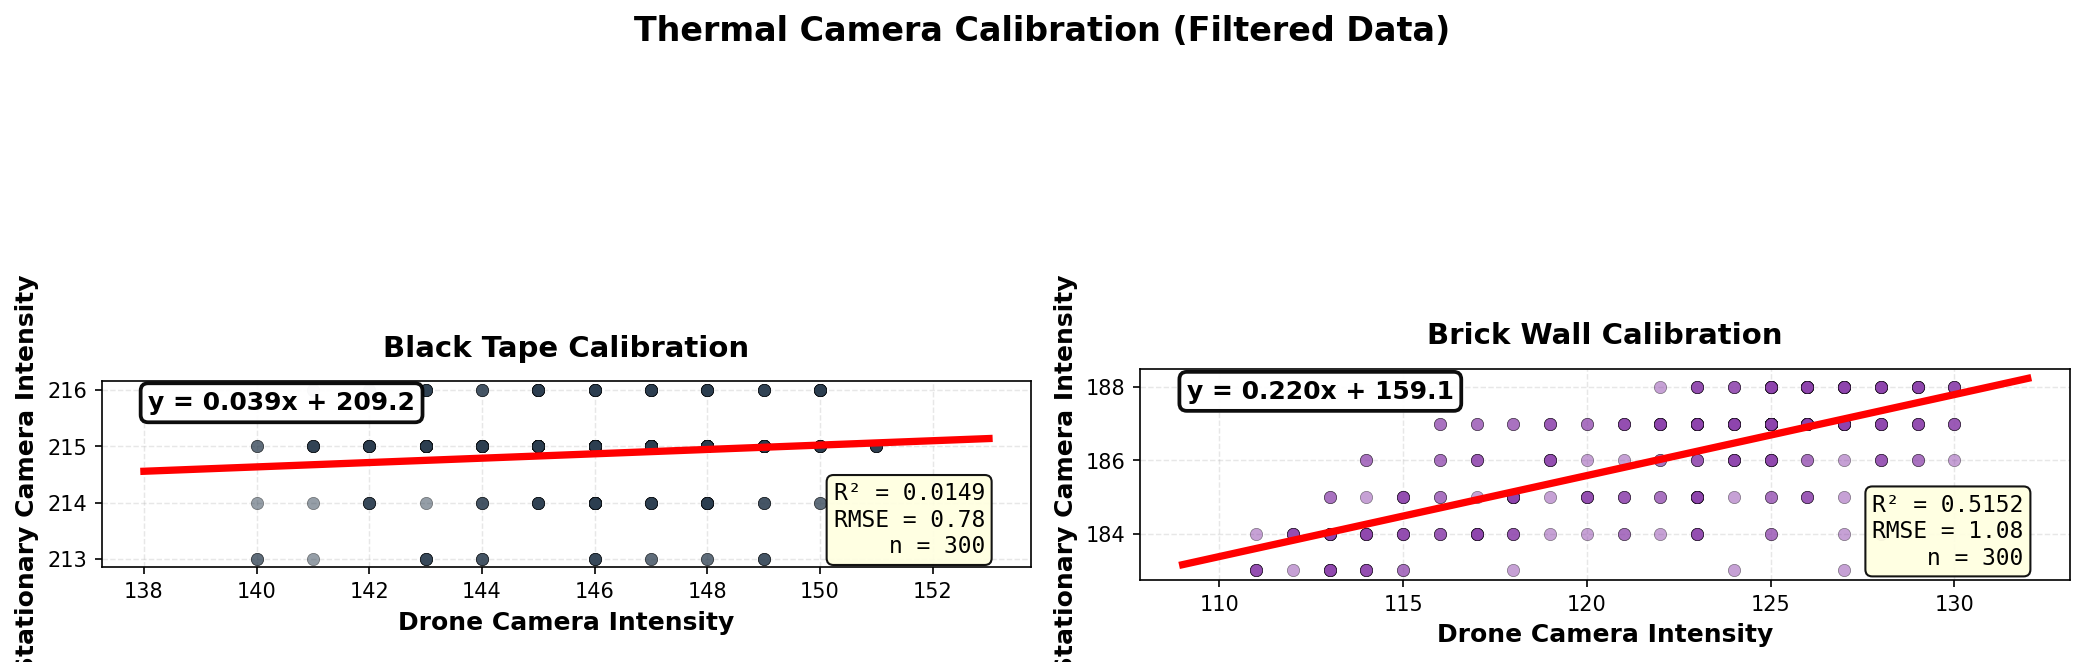


✓ Calibration complete with cleaned data
  Black Tape R² = 0.0149
  Brick Wall R² = 0.5152


In [14]:
# =============================================
# PLOT WITH CLEANED DATA
# =============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

colors = ['#2c3e50', '#8e44ad']

for idx, (ax, data) in enumerate(zip(axes, roi_data)):
    # Scatter
    ax.scatter(data['drone'], data['stat'], 
               alpha=0.5, s=35, color=colors[idx], 
               edgecolors='black', linewidth=0.3)
    
    # Fit line
    x_range = np.linspace(data['drone'].min()-2, data['drone'].max()+2, 100)
    y_fit = data['slope'] * x_range + data['intercept']
    ax.plot(x_range, y_fit, 'r-', linewidth=3.5, label='Linear fit')
    
    # Equation in box
    equation_text = f"y = {data['slope']:.3f}x + {data['intercept']:.1f}"
    ax.text(0.05, 0.95, equation_text, transform=ax.transAxes,
            fontsize=12, verticalalignment='top', fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.95, 
                      edgecolor='black', linewidth=1.8))
    
    # Stats in separate box
    stats_text = f"R² = {data['r2']:.4f}\nRMSE = {data['rmse']:.2f}\nn = {data['n']}"
    ax.text(0.95, 0.05, stats_text, transform=ax.transAxes,
            fontsize=11, ha='right', va='bottom', family='monospace',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.92))
    
    # Labels and title
    ax.set_xlabel('Drone Camera Intensity', fontsize=12, fontweight='bold')
    ax.set_ylabel('Stationary Camera Intensity', fontsize=12, fontweight='bold')
    ax.set_title(f'{data["name"]} Calibration', fontsize=14, fontweight='bold', pad=12)
    
    # Professional grid
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    
    # Equal aspect
    ax.set_aspect('equal', adjustable='box')

plt.suptitle('Thermal Camera Calibration (Filtered Data)', 
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

print(f"\n✓ Calibration complete with cleaned data")
print(f"  Black Tape R² = {roi_data[0]['r2']:.4f}")
print(f"  Brick Wall R² = {roi_data[1]['r2']:.4f}")